Name Muhtasim Haque Nahian

Labpartner(s)

In [14]:
#import statements go here
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

# Class 7.2

Today your assignment is the rest of the pandas unit and to catch up and think about your project topic, which is due by Sunday 10/13.

**W.1** Implement a function that takes as input three variables, and returns the largest of the three. Do this without using the Python max() function.

The goal of this exercise is to think about some internals that Python normally takes care of for us. All you need is some variables and if statements.

In [6]:
def largest(a, b, c):
    largest = a

    if b > largest:
        largest = b

    if c > largest:
        largest = c

    return largest

a = float(input("Enter the first number: "))
b = float(input("Enter the second number: "))
c = float(input("Enter the third number: "))

print("The largest number is:", largest(a, b, c))

Enter the first number:  5
Enter the second number:  3
Enter the third number:  8


The largest number is: 8.0


# Lecture 7.2

### Agenda:

- Questions
- Tropical Tidbits
- Movie project!

### Questions

For our project this week, I am unleashing you use LLMs for coding, and specifically how to make a series of images into a playable movie. For example, say you have a series of daily HYCOM SST plots, and you want to animate this, how would you do it? We'll strategize more in class about how to accomplish this as a team and with the help of ChatGPT, Claude, or whatever, and hopefully come up with a few different workflows you can share. 

# Lab 7.2

**E.0** Complete the previous labs if you are behind.

**E.1** Complete Data Manipulation with Pandas Ch 3-4 in datacamp.

**E.2** Make notes for yourself on progamming tecniques and commands you learned in the datacamp chapter above, including examples, comments and explainitory text. You can do this here or in a separate notebook that you link to here. Basically, you are making a cheat sheet for yourself.

## ch 3

### Setting and removing indexes

<table style="margin-left:0; margin-right:auto;">
    <tr><th></th><th>Syntax</th></tr>
    <tr><td>set index</td><td><span style="color:yellow;"><b><i>.set_index()</i></b></span></td></tr>
    <tr><td>resent index keeping its contents</td><td><span style="color:yellow;"><b><i>.reset_index()</i></b></span></td></tr>
    <tr><td>resent index dropping its contents</td><td><span style="color:yellow;"><b><i>.reset_index(drop=True)</i></b></span></td></tr>
</table>


### Subsetting using .isin() or .loc[]

<span style="color:green;"><b>temperatures[temperatures["city"].isin(cities)]</b></span>

<span style="color:green;"><b>temperatures_ind.loc[cities]</b></span>


### Sorting index

<table style="margin-left:0; margin-right:auto;">
    <tr><th></th><th>Syntax</th></tr>
    <tr><td>sort index</td><td><span style="color:yellow;"><b><i>.sort_index()</i></b></span></td></tr>
    <tr><td>sort index by one column value</td><td><span style="color:yellow;"><b><i>.sort_index(level="column1")</i></b></span></td></tr>
    <tr><td>sort index by ascending one column and descending other</td><td><span style="color:yellow;"><b><i>.sort_index(level=["column1", "column2"], ascending=[True, False]</i></b></span></td></tr>
</table>



### Slicing index values

Slicing lets you select consecutive elements of an object using first:last syntax. You can only slice an index if the index is sorted.


<span style="color:yellow;"><b><i>.loc["column_initial":"column_final"]</i></b></span>


### Slicing in both directions (rows and columns)

<span style="color:green;"><b>temperatures_srt.loc[("India", "Hyderabad"):("Iraq", "Baghdad"), "date":"avg_temp_c"]</b></span>


### Subsetting by row/column number

<table style="margin-left:0; margin-right:auto;">
<tr><th>Example instruction</th><th>Syntax</th></tr>
    <tr><td>23rd row, 2nd column</td><td><span style="color:yellow;"><b><i>.iloc[22, 1]</i></b></span></td></tr>
    <tr><td>the first 5 rows</td><td><span style="color:yellow;"><b><i>.iloc[:5]</i></b></span></td></tr>
    <tr><td>columns 3 to 4</td><td><span style="color:yellow;"><b><i>.iloc[:, 2:4]</i></b></span></td></tr>
    <tr><td>in both directions at once</td><td><span style="color:yellow;"><b><i>.iloc[:5, 2:4]</i></b></span></td></tr>
</table>


### Calculating on a table

<span style="color:yellow;"><b><i>.mean(axis=0)</i></b></span> averages down

<span style="color:yellow;"><b><i>.mean(axis=1)</i></b></span> averages across

In [24]:
# ch 4
# visualizing dataframe

# loading data

url = "https://assets.datacamp.com/production/repositories/5386/datasets/5528f46cc712c9083a6881f787fc9b34ab53d5ea/avoplotto.pkl"
avocados = pd.read_pickle(url)
print(avocados.head())

         date          type  year  avg_price   size     nb_sold
0  2015-12-27  conventional  2015       0.95  small  9626901.09
1  2015-12-20  conventional  2015       0.98  small  8710021.76
2  2015-12-13  conventional  2015       0.93  small  9855053.66
3  2015-12-06  conventional  2015       0.89  small  9405464.36
4  2015-11-29  conventional  2015       0.99  small  8094803.56


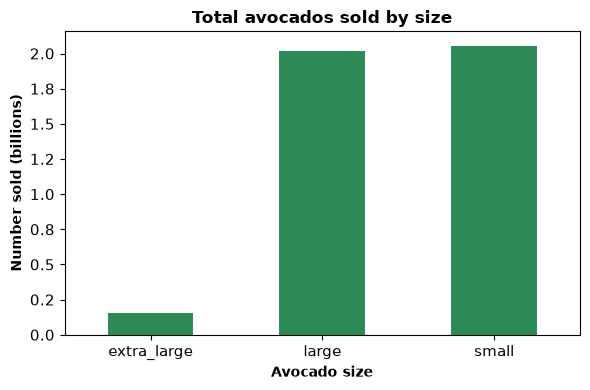

In [38]:
# bar plot of the number of avocados sold by size

nb_sold_by_size = avocados.groupby("size")["nb_sold"].sum()
ax = nb_sold_by_size.plot(kind="bar", figsize=(6,4), color="seagreen")

ax.set_xlabel("Avocado size", fontweight="bold")
ax.set_ylabel("Number sold (billions)", fontweight="bold")
ax.set_title("Total avocados sold by size", fontweight="bold")
ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: f"{x / 1e9:.1f}"))   # lambda creates a small function without giving it a name
ax.tick_params(axis="x", labelrotation=0)
ax.tick_params(axis="both", labelsize=11)

plt.tight_layout()
plt.show()

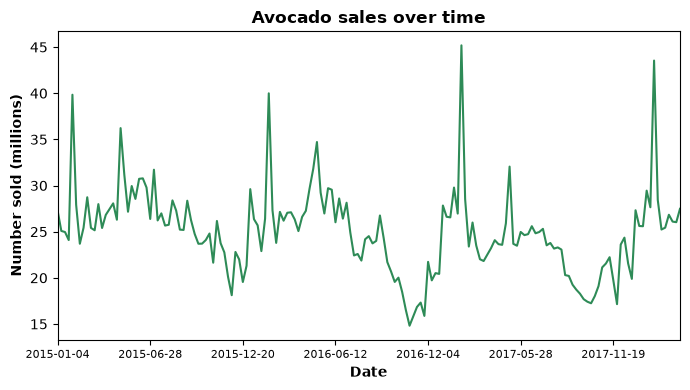

In [39]:
# line plot of the number of avocados sold by date

nb_sold_by_date = avocados.groupby("date")["nb_sold"].sum()
ax = nb_sold_by_date.plot(kind="line", figsize=(7,4), color="seagreen", linewidth=1.5)

ax.set_xlabel("Date", fontweight="bold")
ax.set_ylabel("Number sold (millions)", fontweight="bold")
ax.set_title("Avocado sales over time", fontweight="bold")

ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: f"{x / 1e6:.0f}"))
ax.tick_params(axis="x", labelrotation=0, labelsize=8)
ax.margins(x=0)

plt.tight_layout()
plt.show()

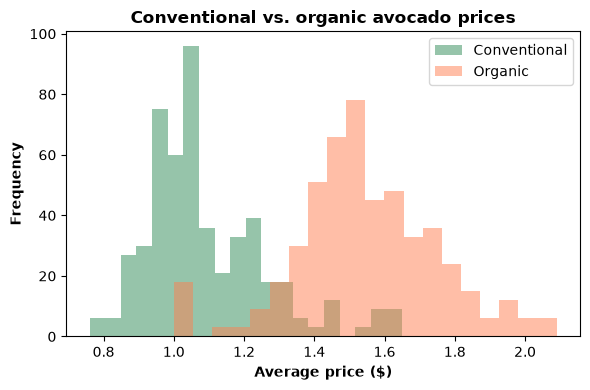

In [50]:
# Histogram of conventional avg_price and organice avg_price

fig, ax = plt.subplots(figsize=(6,4))
avocados[avocados["type"] == "conventional"]["avg_price"].hist(ax=ax, alpha=0.5, bins=20, color="seagreen", label="Conventional")
avocados[avocados["type"] == "organic"]["avg_price"].hist(ax=ax, alpha=0.5, bins=20, color="coral", label="Organic")

ax.set_xlabel("Average price ($)", fontweight="bold")
ax.set_ylabel("Frequency", fontweight="bold")
ax.set_title("Conventional vs. organic avocado prices", fontweight="bold")
ax.tick_params(axis="both")
ax.legend()
ax.grid(False)

plt.tight_layout()
plt.show()

### Finding missing values

<table style="margin-left:0; margin-right:auto;">
<tr><th></th><th>Syntax</th></tr>
    <tr><td>check individual values</td><td><span style="color:yellow;"><b><i>.isna()</i></b></span></td></tr>
    <tr><td>check each column</td><td><span style="color:yellow;"><b><i>.isna().any()</i></b></span></td></tr>
    <tr><td>remove missing values</td><td><span style="color:yellow;"><b><i>.dropna()</i></b></span></td></tr>
</table>

In [64]:
# creating a dataframe

avocados_list = [
    {"date": "2019-11-03", "small_sold": 10376832, "large_sold": 7835071},
    {"date": "2019-11-10", "small_sold": 10717154, "large_sold": 8561348},
]

avocados_2019 = pd.DataFrame(avocados_list)     # converts list into DataFrame

avocados_2019.head()

,date,small_sold,large_sold
0,2019-11-03,10376832,7835071
1,2019-11-10,10717154,8561348


### CSV to DataFrame

<span style="color:green;"><b>airline_bumping = pd.read_csv("airline_bumping.csv")</b></span>

### DataFrame to CSV

<span style="color:green;"><b>airline_bumping.to_csv("airline_bumping.csv")</b></span>

**E.3** For this week's project, find a series of images you want to animate. This can be model output, a series of other plots, whatever you want. Everyone needs to pick their own dataset. Work together and share ideas for different ways to make these movies, and work with an LLM to help you figure this out. Next week on Monday or Wednesday you will present your movie and tell us how you made it.

In [66]:
%pip install imageio-ffmpeg

   ---------------------------------------- 0.0/31.2 MB ? eta -:--:--
   --- ------------------------------------ 2.9/31.2 MB 20.8 MB/s eta 0:00:02
   ------- -------------------------------- 5.8/31.2 MB 16.8 MB/s eta 0:00:02
   --------- ------------------------------ 7.1/31.2 MB 12.8 MB/s eta 0:00:02
   ----------- ---------------------------- 8.7/31.2 MB 11.0 MB/s eta 0:00:03
   ------------- -------------------------- 10.2/31.2 MB 10.1 MB/s eta 0:00:03
   -------------- ------------------------- 11.5/31.2 MB 9.5 MB/s eta 0:00:03
   ---------------- ----------------------- 12.8/31.2 MB 9.0 MB/s eta 0:00:03
   ------------------ --------------------- 14.2/31.2 MB 8.7 MB/s eta 0:00:02
   -------------------- ------------------- 15.7/31.2 MB 8.4 MB/s eta 0:00:02
   --------------------- ------------------ 17.0/31.2 MB 8.2 MB/s eta 0:00:02
   ----------------------- ---------------- 18.6/31.2 MB 8.1 MB/s eta 0:00:02
   ------------------------- -------------- 20.2/31.2 MB 8.0 MB/s eta 0

In [72]:
%pip install pydap

   ---------------------------------------- 0.0/2.5 MB ? eta -:--:--
   ---------------------------------- ----- 2.1/2.5 MB 12.9 MB/s eta 0:00:01
   ---------------------------------------- 2.5/2.5 MB 12.0 MB/s  0:00:00
   ---------------------------------------- 0.0/4.1 MB ? eta -:--:--
   ---------------------------- ----------- 2.9/4.1 MB 13.1 MB/s eta 0:00:01
   ---------------------------------------- 4.1/4.1 MB 12.5 MB/s  0:00:00

   ---------------------------------------- 0/6 [url-normalize]
   ---------------------------------------- 0/6 [url-normalize]
   ------ --------------------------------- 1/6 [lxml]
   ------ --------------------------------- 1/6 [lxml]
   ------ --------------------------------- 1/6 [lxml]
   ------ --------------------------------- 1/6 [lxml]
   ------ --------------------------------- 1/6 [lxml]
   ------ --------------------------------- 1/6 [lxml]
   -------------------- ------------------- 3/6 [webob]
   -------------------- ------------------- 3

In [67]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as colors
import matplotlib.animation as animation

import cartopy.crs as ccrs
import cartopy.feature as cfeature

from IPython.display import display, Image, Video
from pathlib import Path
import imageio_ffmpeg

In [68]:
# HYCOM Gulf of Mexico reanalysis: approximately 4-km resolution
url = "https://tds.hycom.org/thredds/dodsC/GOMb0.04/reanalysis/2019/2d"

# Period to animate
start_date = "2019-05-17T00:00:00"
end_date = "2019-05-19T23:00:00"

# Map boundaries: northern Gulf of Mexico
west = -94
east = -86
south = 26
north = 30.5

# Keep every sixth grid point to avoid overcrowding the arrows
spatial_step = 6

# Keep every hourly time step
time_step = 1

# Movie playback speed: frames per second
fps = 6

# Create an output folder beside your notebook
output_folder = Path("hycom_animation_output")
output_folder.mkdir(exist_ok=True)

print("Output folder:", output_folder.resolve())

Output folder: C:\Users\ASUS\Desktop\OCS 7001\hycom_animation_output


In [69]:
import re
import urllib.request
import xml.etree.ElementTree as ET
from datetime import datetime, timedelta
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from matplotlib.animation import FuncAnimation, PillowWriter, FFMpegWriter
import xarray as xr
from netCDF4 import num2date
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from IPython.display import HTML, display

START = datetime(2026, 10, 6)
END = datetime(2026, 10, 11)  # Exclusive: includes all of October 10
EXTENT = [-91, -84, 26, 31]  # West, east, south, north
ELEMENT_STRIDE = 100
ARROW_SPACING = 0.15         # Approximate spacing in degrees
FPS = 3                      # Frames per second in the movie
BASE = "https://opendap.co-ops.nos.noaa.gov/thredds"

In [70]:
urls = []
day = START
while day < END:
    catalog = f"{BASE}/catalog/NOAA/NGOFS2/MODELS/{day:%Y/%m/%d}/catalog.xml"
    try:
        with urllib.request.urlopen(catalog, timeout=60) as response:
            root = ET.fromstring(response.read())
    except Exception as exc:
        raise RuntimeError(f"Cannot read NOAA catalog for {day:%Y-%m-%d}: {catalog}") from exc
    paths = sorted({
        node.attrib["urlPath"] for node in root.iter()
        if "urlPath" in node.attrib
        and re.search(r"ngofs2\.t\d{2}z\.\d{8}\.fields\.n006\.nc$",
                      node.attrib["urlPath"])
    })
    if not paths:
        raise RuntimeError(f"No final-nowcast files listed for {day:%Y-%m-%d}.")
    urls.extend(f"{BASE}/dodsC/{path}" for path in paths)
    print(f"{day:%Y-%m-%d}: {len(paths)} files")
    day += timedelta(days=1)

print(f"Found {len(urls)} online files.")
print("Example:", urls[0])

2026-10-06: 4 files
2026-10-07: 4 files
2026-10-08: 4 files
2026-10-09: 4 files
2026-10-10: 4 files
Found 20 online files.
Example: https://opendap.co-ops.nos.noaa.gov/thredds/dodsC/NOAA/NGOFS2/MODELS/2026/10/06/ngofs2.t03z.20261006.fields.n006.nc


In [76]:
import numpy as np
import xarray as xr
from requests.exceptions import ConnectionError, Timeout


def as_float(values):
    """Convert NetCDF values to NumPy arrays with NaN for missing values."""
    return np.ma.asarray(values, dtype=np.float64).filled(np.nan)


def open_remote(url):
    """Open the online dataset without saving a data file."""
    return xr.open_dataset(
        url,
        engine="pydap",
        decode_times=False,
        backend_kwargs={"timeout": 300}
    )


def read_nodes_in_batches(variable, nodes, label, batch_size=2000):
    """Read a node-based variable using small requests."""

    # Put the node dimension last.
    other_dims = [dim for dim in variable.dims if dim != "node"]
    variable = variable.transpose(*other_dims, "node")

    # Find the unique nodes needed by our selected triangles.
    unique_nodes, inverse = np.unique(
        nodes,
        return_inverse=True
    )
    inverse = inverse.ravel()

    leading_shape = tuple(variable.sizes[dim] for dim in other_dims)

    selected = np.empty(
        leading_shape + (len(unique_nodes),),
        dtype=np.float64
    )

    # Group nodes into small ranges.
    batch_ids = unique_nodes // batch_size
    batches = np.unique(batch_ids)

    for number, batch_id in enumerate(batches, start=1):
        positions = np.flatnonzero(batch_ids == batch_id)
        needed = unique_nodes[positions]

        start = int(needed.min())
        stop = int(needed.max()) + 1

        print(
            f"Reading {label}: batch {number}/{len(batches)} "
            f"({stop - start} nodes)...",
            flush=True
        )

        # Try each request up to three times.
        for attempt in range(1, 4):
            try:
                # Select a small range before reading from NOAA.
                block = as_float(
                    variable.isel(node=slice(start, stop))
                )
                break

            except (ConnectionError, Timeout):
                if attempt == 3:
                    raise

                print(
                    f"  Connection timed out. Retrying "
                    f"(attempt {attempt + 1}/3)...",
                    flush=True
                )

        selected[..., positions] = block[..., needed - start]

    # Restore the original triangle-node arrangement.
    return selected[..., inverse].reshape(
        leading_shape + nodes.shape
    )


# Sample every ELEMENT_STRIDE-th triangle.
sample = slice(None, None, ELEMENT_STRIDE)

print("Connecting to NOAA...", flush=True)

with open_remote(urls[0]) as ds:

    # Check that the required variables exist.
    required = {
        "u", "v", "siglev", "h", "nv",
        "lonc", "latc", "zeta", "wet_cells"
    }

    missing = required.difference(ds.variables)

    if missing:
        raise ValueError(f"Required variables missing: {missing}")

    mesh_sizes = (ds.sizes["node"], ds.sizes["nele"])

    # Read the sampled triangle locations.
    print("Reading sampled longitude...", flush=True)
    sample_lon = (
        as_float(ds["lonc"][sample]) + 180
    ) % 360 - 180

    print("Reading sampled latitude...", flush=True)
    sample_lat = as_float(ds["latc"][sample])

    west, east, south, north = EXTENT

    # Find sampled triangles inside the map boundaries.
    inside = np.flatnonzero(
        (sample_lon >= west)
        & (sample_lon <= east)
        & (sample_lat >= south)
        & (sample_lat <= north)
    )

    if inside.size == 0:
        raise ValueError("No sampled cells in the selected region.")

    # Keep one arrow per spacing box to avoid overcrowding.
    boxes = np.column_stack([
        np.floor((sample_lon[inside] - west) / ARROW_SPACING),
        np.floor((sample_lat[inside] - south) / ARROW_SPACING)
    ])

    _, first_in_box = np.unique(
        boxes,
        axis=0,
        return_index=True
    )

    keep = np.sort(inside[first_in_box])

    lon = sample_lon[keep]
    lat = sample_lat[keep]

    # Read the three node numbers for each selected triangle.
    print("Reading triangle connectivity...", flush=True)

    nodes = (
        np.asarray(ds["nv"][:, sample], dtype=int)[:, keep] - 1
    )

    if nodes.min() < 0 or nodes.max() >= mesh_sizes[0]:
        raise ValueError("Unexpected FVCOM node numbering.")

    # Read bathymetry in small batches.
    # Output dimensions: triangle corner, cell.
    h_nodes = read_nodes_in_batches(
        ds["h"],
        nodes,
        label="bathymetry",
        batch_size=2000
    )

    # Read vertical interfaces in small batches.
    # Output dimensions: interface, triangle corner, cell.
    sigma_nodes = read_nodes_in_batches(
        ds["siglev"],
        nodes,
        label="vertical mesh",
        batch_size=2000
    )

    # Check that interfaces run from surface (0) to bottom (-1).
    if not (
        np.allclose(sigma_nodes[0], 0, atol=1e-5)
        and np.allclose(sigma_nodes[-1], -1, atol=1e-5)
        and np.all(np.diff(sigma_nodes, axis=0) < 0)
    ):
        raise ValueError(
            "Unexpected sigma interfaces; inspect before averaging."
        )

    # Calculate fractional layer thicknesses.
    # Output dimensions: layer, triangle corner, cell.
    dsigma = -np.diff(sigma_nodes, axis=0)

    del sigma_nodes

print(f"Using {len(lon)} arrow locations.")

Connecting to NOAA...


E:\Anaconda\Anaconda_installed\Lib\site-packages\pydap\handlers\dap.py:164: UserWarning: PyDAP was unable to determine the DAP protocol defaulting to DAP2. DAP2 is consider legacy and may result in slower responses. 
Consider replacing `http` in your `url` with either `dap2` or `dap4` to specify the DAP protocol (e.g. `dap2://<data_url>` or `dap4://<data_url>`).  For more 
information, go to https://www.opendap.org/faq-page.
  warnings.warn(


Reading sampled longitude...
Reading sampled latitude...
Reading triangle connectivity...
Reading bathymetry: batch 1/102 (1816 nodes)...
Reading bathymetry: batch 2/102 (1714 nodes)...
Reading bathymetry: batch 3/102 (1789 nodes)...
Reading bathymetry: batch 4/102 (1518 nodes)...
Reading bathymetry: batch 5/102 (1807 nodes)...
Reading bathymetry: batch 6/102 (1128 nodes)...
Reading bathymetry: batch 7/102 (1282 nodes)...
Reading bathymetry: batch 8/102 (1444 nodes)...
Reading bathymetry: batch 9/102 (1503 nodes)...
Reading bathymetry: batch 10/102 (1333 nodes)...
Reading bathymetry: batch 11/102 (1380 nodes)...
Reading bathymetry: batch 12/102 (1594 nodes)...
Reading bathymetry: batch 13/102 (1311 nodes)...
Reading bathymetry: batch 14/102 (1364 nodes)...
Reading bathymetry: batch 15/102 (1606 nodes)...
Reading bathymetry: batch 16/102 (1376 nodes)...
Reading bathymetry: batch 17/102 (1481 nodes)...
Reading bathymetry: batch 18/102 (1442 nodes)...
Reading bathymetry: batch 19/102 (108

In [78]:
import numpy as np
import time
from datetime import datetime, timedelta
from netCDF4 import num2date
from requests.exceptions import ConnectionError, Timeout


# --------------------------------------------------
# 1. Retry a request if the connection times out
# --------------------------------------------------
def read_with_retry(get_values, label):
    for attempt in range(1, 4):
        try:
            return as_float(get_values())

        except (ConnectionError, Timeout):
            if attempt == 3:
                print(
                    f"Failed to read {label}. "
                    "Rerun this cell to resume from completed frames.",
                    flush=True
                )
                raise

            print(
                f"  Timeout reading {label}. "
                f"Retrying: attempt {attempt + 1}/3...",
                flush=True
            )

            time.sleep(3)


# --------------------------------------------------
# 2. Read velocity in small groups of layers
# --------------------------------------------------
def read_velocity(ds, name, ti):
    variable = ds[name]

    # Expected dimensions: time, vertical layer, triangle.
    time_dim, layer_dim, cell_dim = variable.dims

    parts = []
    layers_per_request = 5

    for first in range(
        0,
        variable.sizes[layer_dim],
        layers_per_request
    ):
        last = min(
            first + layers_per_request,
            variable.sizes[layer_dim]
        )

        print(
            f"    Reading {name}: layers {first + 1}–{last}...",
            flush=True
        )

        part = read_with_retry(
            lambda: variable.isel({
                time_dim: ti,
                layer_dim: slice(first, last),
                cell_dim: sample
            }),
            f"{name}, layers {first + 1}–{last}"
        )

        # Keep the arrow locations selected by the mesh cell.
        parts.append(part[:, keep])

    return np.concatenate(parts, axis=0)


# --------------------------------------------------
# 3. Calculate depth-averaged velocities
# --------------------------------------------------
def depth_average(u, v, thickness, wet):
    good = (
        wet
        & np.all(np.isfinite(u) & np.isfinite(v), axis=0)
        & np.all(
            np.isfinite(thickness) & (thickness > 0),
            axis=0
        )
    )

    ubar = np.full(u.shape[1], np.nan)
    vbar = np.full(v.shape[1], np.nan)

    weights = thickness[:, good]

    ubar[good] = (
        np.sum(u[:, good] * weights, axis=0)
        / weights.sum(axis=0)
    )

    vbar[good] = (
        np.sum(v[:, good] * weights, axis=0)
        / weights.sum(axis=0)
    )

    return ubar, vbar


# --------------------------------------------------
# 4. Keep completed frames from the interrupted run
# --------------------------------------------------
# Dates, region, and mesh settings must remain unchanged.
if "records" not in globals():
    records = []

completed_times = {row[0] for row in records}

print(
    f"Keeping {len(completed_times)} completed frames in memory.",
    flush=True
)


# --------------------------------------------------
# 5. Read the remaining frames directly from NOAA
# --------------------------------------------------
for number, url in enumerate(urls, start=1):
    print(
        f"\nChecking file {number}/{len(urls)}...",
        flush=True
    )

    with open_remote(url) as ds:

        # Confirm that the mesh dimensions match.
        current_sizes = (
            ds.sizes["node"],
            ds.sizes["nele"]
        )

        if current_sizes != mesh_sizes:
            raise ValueError(
                "Model mesh changed during the selected period."
            )

        # Read the timestamps.
        tv = ds["time"]

        time_values = read_with_retry(
            lambda: tv,
            "timestamps"
        )

        dates = num2date(
            time_values,
            tv.attrs["units"],
            calendar=tv.attrs.get("calendar", "standard")
        )

        # Identify frames that still need to be read.
        pending = []

        for ti, date in enumerate(dates):
            stamp = datetime(
                date.year,
                date.month,
                date.day,
                date.hour,
                date.minute,
                date.second
            )

            if START <= stamp < END:
                if stamp not in completed_times:
                    pending.append((ti, stamp))

        if not pending:
            print(
                "  Already completed or outside selected dates.",
                flush=True
            )
            continue

        # Confirm that cell locations match the original mesh.
        check_lon = (
            read_with_retry(
                lambda: ds["lonc"][sample],
                "longitude"
            ) + 180
        ) % 360 - 180

        check_lat = read_with_retry(
            lambda: ds["latc"][sample],
            "latitude"
        )

        if not (
            np.allclose(check_lon, sample_lon)
            and np.allclose(check_lat, sample_lat)
        ):
            raise ValueError("Model cell positions changed.")

        # Process each unfinished timestamp.
        for ti, stamp in pending:
            print(
                f"\n  Processing {stamp} UTC...",
                flush=True
            )

            # Read eastward and northward velocities.
            u = read_velocity(ds, "u", ti)
            v = read_velocity(ds, "v", ti)

            # Read sea level in small node batches.
            # Uses the function from your corrected mesh cell.
            zeta_variable = ds["zeta"]
            zeta_time_dim = zeta_variable.dims[0]

            zeta_nodes = read_nodes_in_batches(
                zeta_variable.isel({
                    zeta_time_dim: ti
                }),
                nodes,
                label="sea level",
                batch_size=2000
            )

            # Total water depth at each triangle corner.
            depth_nodes = h_nodes + zeta_nodes

            # Calculate layer thickness at each triangle
            # by averaging across its three corners.
            thickness = np.mean(
                dsigma * depth_nodes[None, :, :],
                axis=1
            )

            # Identify wet cells.
            wet = (
                read_with_retry(
                    lambda: ds["wet_cells"][ti, sample],
                    "wet-cell flags"
                )[keep] == 1
            )

            wet &= np.all(depth_nodes > 0, axis=0)

            # Calculate depth-averaged u and v.
            ub, vb = depth_average(
                u,
                v,
                thickness,
                wet
            )

            # Keep the frame only after processing succeeds.
            records.append((stamp, ub, vb))
            completed_times.add(stamp)

            print(
                f"  Completed: {stamp} UTC — "
                f"{np.isfinite(ub).sum()} valid arrows.",
                flush=True
            )


# --------------------------------------------------
# 6. Prepare arrays for plotting and animation
# --------------------------------------------------
records.sort(key=lambda row: row[0])

if len(records) < 2:
    raise RuntimeError(
        "Fewer than two frames are available."
    )

times = [row[0] for row in records]

if len(set(times)) != len(times):
    raise ValueError(
        "Duplicate timestamps found."
    )

# This notebook uses frames spaced six hours apart.
if any(
    b - a != timedelta(hours=6)
    for a, b in zip(times, times[1:])
):
    raise ValueError(
        "Unexpected time gaps; inspect files before animating."
    )

U = np.stack([row[1] for row in records])
V = np.stack([row[2] for row in records])

SPEED = np.hypot(U, V)

if not np.isfinite(SPEED).any():
    raise ValueError(
        "No valid ocean currents were found."
    )

print(
    f"\nReady: {len(times)} frames, "
    f"{times[0]} to {times[-1]} UTC"
)

Keeping 9 completed frames in memory.

Checking file 1/20...


E:\Anaconda\Anaconda_installed\Lib\site-packages\pydap\handlers\dap.py:164: UserWarning: PyDAP was unable to determine the DAP protocol defaulting to DAP2. DAP2 is consider legacy and may result in slower responses. 
Consider replacing `http` in your `url` with either `dap2` or `dap4` to specify the DAP protocol (e.g. `dap2://<data_url>` or `dap4://<data_url>`).  For more 
information, go to https://www.opendap.org/faq-page.
  warnings.warn(


  Already completed or outside selected dates.

Checking file 2/20...


E:\Anaconda\Anaconda_installed\Lib\site-packages\pydap\handlers\dap.py:164: UserWarning: PyDAP was unable to determine the DAP protocol defaulting to DAP2. DAP2 is consider legacy and may result in slower responses. 
Consider replacing `http` in your `url` with either `dap2` or `dap4` to specify the DAP protocol (e.g. `dap2://<data_url>` or `dap4://<data_url>`).  For more 
information, go to https://www.opendap.org/faq-page.
  warnings.warn(


  Already completed or outside selected dates.

Checking file 3/20...


...


  Processing 2026-10-10 09:00:00 UTC...
    Reading u: layers 1–5...
    Reading u: layers 6–10...
    Reading u: layers 11–15...
    Reading u: layers 16–20...
    Reading u: layers 21–25...
    Reading u: layers 26–30...
    Reading u: layers 31–35...
    Reading u: layers 36–40...
    Reading v: layers 1–5...
    Reading v: layers 6–10...
    Reading v: layers 11–15...
    Reading v: layers 16–20...
    Reading v: layers 21–25...
    Reading v: layers 26–30...
    Reading v: layers 31–35...
    Reading v: layers 36–40...
Reading sea level: batch 1/102 (1816 nodes)...
Reading sea level: batch 2/102 (1714 nodes)...
Reading sea level: batch 3/102 (1789 nodes)...
Reading sea level: batch 4/102 (1518 nodes)...
Reading sea level: batch 5/102 (1807 nodes)...
Reading sea level: batch 6/102 (1128 nodes)...
Reading sea level: batch 7/102 (1282 nodes)...
Reading sea level: batch 8/102 (1444 nodes)...
Reading sea level: batch 9/102 (1503 nodes)...
Reading sea level: batch 10/102 (1333 nodes)..

E:\Anaconda\Anaconda_installed\Lib\site-packages\pydap\handlers\dap.py:164: UserWarning: PyDAP was unable to determine the DAP protocol defaulting to DAP2. DAP2 is consider legacy and may result in slower responses. 
Consider replacing `http` in your `url` with either `dap2` or `dap4` to specify the DAP protocol (e.g. `dap2://<data_url>` or `dap4://<data_url>`).  For more 
information, go to https://www.opendap.org/faq-page.
  warnings.warn(



  Processing 2026-10-10 15:00:00 UTC...
    Reading u: layers 1–5...
    Reading u: layers 6–10...
    Reading u: layers 11–15...
    Reading u: layers 16–20...
    Reading u: layers 21–25...
    Reading u: layers 26–30...
    Reading u: layers 31–35...
    Reading u: layers 36–40...
    Reading v: layers 1–5...
    Reading v: layers 6–10...
    Reading v: layers 11–15...
    Reading v: layers 16–20...
    Reading v: layers 21–25...
    Reading v: layers 26–30...
    Reading v: layers 31–35...
    Reading v: layers 36–40...
Reading sea level: batch 1/102 (1816 nodes)...
Reading sea level: batch 2/102 (1714 nodes)...
Reading sea level: batch 3/102 (1789 nodes)...
Reading sea level: batch 4/102 (1518 nodes)...
Reading sea level: batch 5/102 (1807 nodes)...
Reading sea level: batch 6/102 (1128 nodes)...
Reading sea level: batch 7/102 (1282 nodes)...
Reading sea level: batch 8/102 (1444 nodes)...
Reading sea level: batch 9/102 (1503 nodes)...
Reading sea level: batch 10/102 (1333 nodes)..

E:\Anaconda\Anaconda_installed\Lib\site-packages\pydap\handlers\dap.py:164: UserWarning: PyDAP was unable to determine the DAP protocol defaulting to DAP2. DAP2 is consider legacy and may result in slower responses. 
Consider replacing `http` in your `url` with either `dap2` or `dap4` to specify the DAP protocol (e.g. `dap2://<data_url>` or `dap4://<data_url>`).  For more 
information, go to https://www.opendap.org/faq-page.
  warnings.warn(



  Processing 2026-10-10 21:00:00 UTC...
    Reading u: layers 1–5...
    Reading u: layers 6–10...
    Reading u: layers 11–15...
    Reading u: layers 16–20...
    Reading u: layers 21–25...
    Reading u: layers 26–30...
    Reading u: layers 31–35...
    Reading u: layers 36–40...
    Reading v: layers 1–5...
    Reading v: layers 6–10...
    Reading v: layers 11–15...
    Reading v: layers 16–20...
    Reading v: layers 21–25...
    Reading v: layers 26–30...
    Reading v: layers 31–35...
    Reading v: layers 36–40...
Reading sea level: batch 1/102 (1816 nodes)...
Reading sea level: batch 2/102 (1714 nodes)...
Reading sea level: batch 3/102 (1789 nodes)...
Reading sea level: batch 4/102 (1518 nodes)...
Reading sea level: batch 5/102 (1807 nodes)...
Reading sea level: batch 6/102 (1128 nodes)...
Reading sea level: batch 7/102 (1282 nodes)...
Reading sea level: batch 8/102 (1444 nodes)...
Reading sea level: batch 9/102 (1503 nodes)...
Reading sea level: batch 10/102 (1333 nodes)..

Drawing land...


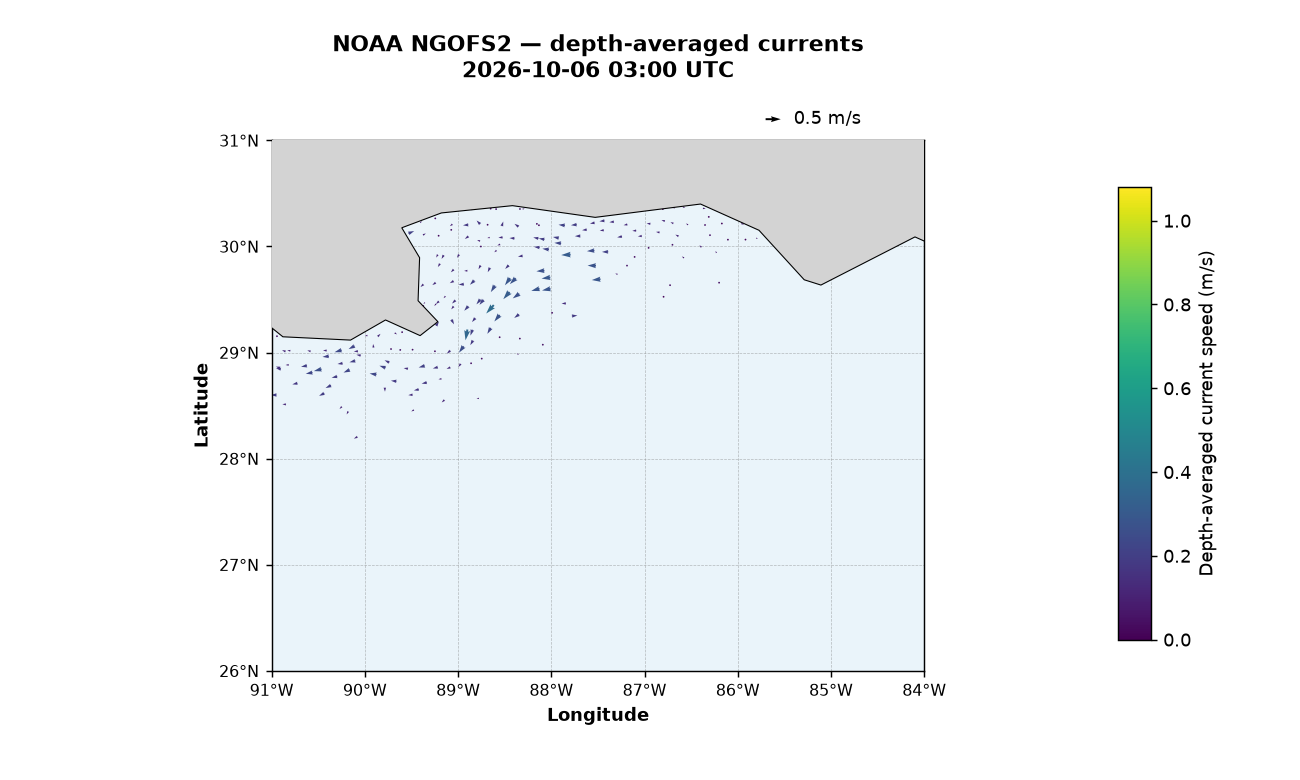

In [81]:
import numpy as np
import matplotlib.pyplot as plt
import cartopy.feature as cfeature

from matplotlib.colors import Normalize
from matplotlib.patches import Polygon
from matplotlib.ticker import FuncFormatter
from IPython.display import display, Image
from io import BytesIO


plt.close("all")

# Map boundaries
west, east, south, north = map(float, EXTENT)

if not (
    -180 <= west < east <= 180
    and -90 < south < north < 90
):
    raise ValueError(
        f"Invalid EXTENT: {EXTENT}. "
        "Expected [west, east, south, north] in degrees."
    )

plot_lon = np.asarray(lon, dtype=float).ravel()
plot_lat = np.asarray(lat, dtype=float).ravel()

if not (
    np.isfinite(plot_lon).all()
    and np.isfinite(plot_lat).all()
):
    raise ValueError("Longitude or latitude contains invalid values.")

if not np.isfinite(SPEED).any():
    raise ValueError("No valid current speeds are available.")


# Create ordinary Matplotlib axes with explicit positions.
fig = plt.figure(figsize=(10, 6), facecolor="white")

ax = fig.add_axes([0.10, 0.14, 0.72, 0.68])
cax = fig.add_axes([0.86, 0.18, 0.025, 0.58])

ax.set_facecolor("#eaf4fa")
ax.set_xlim(west, east)
ax.set_ylim(south, north)
ax.set_autoscale_on(False)

# Approximate geographic proportions at the map's central latitude.
middle_latitude = (south + north) / 2
ax.set_aspect(
    1 / np.cos(np.deg2rad(middle_latitude)),
    adjustable="box"
)


# Draw land polygons directly in longitude–latitude coordinates.
# No Cartopy map projection is used.
print("Drawing land...", flush=True)

for geometry in cfeature.LAND.with_scale("110m").geometries():
    polygons = (
        geometry.geoms
        if geometry.geom_type == "MultiPolygon"
        else [geometry]
    )

    for polygon in polygons:
        if polygon.geom_type != "Polygon":
            continue

        xmin, ymin, xmax, ymax = polygon.bounds

        # Skip land completely outside the map.
        if (
            xmax < west or xmin > east
            or ymax < south or ymin > north
        ):
            continue

        coordinates = np.asarray(polygon.exterior.coords)

        ax.add_patch(
            Polygon(
                coordinates,
                closed=True,
                facecolor="lightgray",
                edgecolor="black",
                linewidth=0.6,
                zorder=3
            )
        )


# Fixed speed and arrow scales for all frames.
vmax = max(0.1, float(np.nanmax(SPEED)))
norm = Normalize(vmin=0, vmax=vmax)
arrow_scale = max(4.0, 20 * vmax)

quiver = ax.quiver(
    plot_lon,
    plot_lat,
    np.ma.masked_invalid(U[0]),
    np.ma.masked_invalid(V[0]),
    np.ma.masked_invalid(SPEED[0]),
    cmap="viridis",
    norm=norm,
    angles="uv",
    scale_units="width",
    scale=arrow_scale,
    width=0.003,
    pivot="middle",
    zorder=2
)

ax.quiverkey(
    quiver,
    X=0.78,
    Y=1.04,
    U=0.5,
    label="0.5 m/s",
    coordinates="axes",
    labelpos="E"
)

cbar = fig.colorbar(quiver, cax=cax)
cbar.set_label("Depth-averaged current speed (m/s)")


# Latitude and longitude labels
ax.xaxis.set_major_formatter(
    FuncFormatter(
        lambda x, pos: f"{abs(x):g}°{'W' if x < 0 else 'E'}"
    )
)

ax.yaxis.set_major_formatter(
    FuncFormatter(
        lambda y, pos: f"{abs(y):g}°{'S' if y < 0 else 'N'}"
    )
)

ax.set_xlabel("Longitude", fontweight="bold")
ax.set_ylabel("Latitude", fontweight="bold")

ax.tick_params(labelsize=9)
ax.grid(
    color="gray",
    linestyle="--",
    linewidth=0.4,
    alpha=0.5
)

title = ax.set_title(
    "NOAA NGOFS2 — depth-averaged currents\n"
    f"{times[0]:%Y-%m-%d %H:%M} UTC",
    fontsize=12,
    fontweight="bold",
    pad=35
)


# Display a PNG directly in the notebook.
# The image stays in memory; no file is saved.
buffer = BytesIO()

fig.savefig(
    buffer,
    format="png",
    dpi=130,
    facecolor="white"
)

buffer.seek(0)
display(Image(data=buffer.getvalue()))
buffer.close()

# Retain fig for animation but prevent duplicate notebook output.
plt.close(fig)


In [82]:
def update(frame):
    quiver.set_UVC(np.ma.masked_invalid(U[frame]),
                   np.ma.masked_invalid(V[frame]),
                   np.ma.masked_invalid(SPEED[frame]))
    title.set_text("NOAA NGOFS2 — reconstructed depth-averaged currents\n"
                   f"{times[frame]:%Y-%m-%d %H:%M} UTC")
    return quiver, title

animation = FuncAnimation(fig, update, frames=len(times),
                          interval=1000 / FPS, blit=False)
plt.rcParams["animation.embed_limit"] = 50  # MB for the notebook preview
plt.close(fig)
display(HTML(animation.to_jshtml()))